# RetailPulse — Step 6: Inventory Optimisation

**Goal:** for each of the top 20 products, recommend a **safety stock**, **reorder point** and **order quantity** in units, test the policy in a simulation
against simpler policies, flag what needs action, and check stock rules against the dataset's answer key.

**Formulas** (d = forecast weekly demand, σ = standard deviation of weekly forecast error, L = lead time in weeks):

SS = z · σ · √L  ROP = d · L + SS  EOQ = √(2 · 52d · S / (h · unit cost))

**Assumptions** (the dataset has no supplier data, so these are stated choices):

| Assumption | Value | Why |
|---|---|---|
| Lead time (L) | 1 week | Typical for a domestic supplier |
| Service level | 95% (z ≈ 1.65) | Common retail target |
| Ordering cost (S) | PKR 5,000 per order | Admin, handling and delivery |
| Holding cost (h) | 20% of **cost price** per year | Industry rule of thumb; the dataset has real cost prices |
| Stock pool | One central stock per product (all 30 stores together) | The snapshot covers only a few stores per product (see section 5) |

Code: `src/inventory.py`. Inputs: `sku_weekly.csv` (Step 2) and `sku_forecasts.csv` (Step 5).

## 0. Setup

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.stats import norm

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.cleaning import connect
from src.forecasting import lost_units
from src.inventory import safety_stock, reorder_point, eoq, abc_class, simulate, simulate_naive

PROC = ROOT / 'data' / 'processed'
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.1f}'.format); pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'

SERVICE, L, S, H = 0.95, 1, 5000, 0.20
Z = norm.ppf(SERVICE)
con = connect(ROOT / 'retail_clean_dataset', PROC / 'sales_clean.parquet')
print(f'z = {Z:.3f}')

z = 1.645


## 1. Weekly demand per product
Demand = recorded units + units lost to the known stockouts (same estimate as Step 5), so the stockouts do not make demand look lower than it was.

In [2]:
sku = pd.read_csv(PROC / 'sku_weekly.csv', parse_dates=['week_end'])
lost = lost_units(con, by_sku=True)
lost['week_end'] = lost['date'] + pd.to_timedelta(6 - lost['date'].dt.dayofweek, unit='D')
sku = sku.join(lost.groupby(['sku_id', 'week_end'])['lost_units'].sum(), on=['sku_id', 'week_end']).fillna({'lost_units': 0})
sku['demand'] = sku['units'] + sku['lost_units']
demand = sku.pivot(index='week_end', columns='sku_id', values='demand')
info = sku.drop_duplicates('sku_id').set_index('sku_id')[['sku_name', 'category', 'revenue_rank', 'unit_price', 'cost_price']].sort_values('revenue_rank')
SKUS = info.index.tolist()
demand = demand[SKUS]
print(f'{demand.shape[1]} products x {demand.shape[0]} weeks ({demand.index.min().date()} -> {demand.index.max().date()})')

20 products x 208 weeks (2022-01-09 -> 2025-12-28)


## 2. Which σ? Forecast error, not raw demand variation
The guide's formula uses the standard deviation of weekly demand. Here demand has a strong, *predictable* seasonal pattern (the November–December peak),
which inflates that number even though it is not uncertainty. Safety stock should cover what the forecast **cannot** predict, so σ is the standard deviation
of the forecast error. Below, the two are compared for 2024 using a simple seasonal forecast (same week last year × recent growth, computed only from earlier weeks).

In [3]:
def seasonal_forecast(s):
    """Forecast for each week from data up to the week before: same week last year x growth of the last 8 weeks vs a year earlier."""
    growth = s.shift(1).rolling(8).sum() / s.shift(53).rolling(8).sum()
    return s.shift(52) * growth

fc_hist = demand.apply(seasonal_forecast)
sigma = pd.DataFrame({'std of weekly demand (guide)': demand.loc['2024'].std(),
                      'std of forecast error (used)': (demand - fc_hist).loc['2024'].std(),
                      'avg weekly demand 2024': demand.loc['2024'].mean()})
sigma['ratio'] = sigma.iloc[:, 0] / sigma.iloc[:, 1]
display(sigma.loc[SKUS].head(8))
print(f"raw demand std is {sigma['ratio'].median():.1f}x the forecast-error std for the median product "
      f"(up to {sigma['ratio'].max():.1f}x for {sigma['ratio'].idxmax()})")

,std of weekly demand (guide),std of forecast error (used),avg weekly demand 2024,ratio
sku_id,,,,
SKU04321,858.8,261.8,"5,848.4",3.3
SKU03727,130.5,72.1,830.4,1.8
SKU04329,38.7,35.9,206.4,1.1
SKU04596,225.5,91.8,"1,404.1",2.5
SKU01371,52.9,46.2,352.5,1.1
SKU03053,23.9,24.4,106.2,1.0
SKU01189,28.1,30.8,159.6,0.9
SKU04551,30.5,28.5,146.2,1.1


raw demand std is 1.1x the forecast-error std for the median product (up to 3.3x for SKU04321)


**Insights — choosing σ**
- For most products the two measures are similar, but for the **big sellers the raw demand std is 2–3× larger** than the forecast error (3.3× for the top seller `SKU04321`). Their weekly sales swing a lot, but predictably, with the season.
- Using the raw std would roughly triple the top seller's safety stock, tying up cash in stock that only covers a swing the forecast already expects. Using the forecast error keeps safety stock for real surprises.

## 3. Recommendations for January 2026
- **d** = average Prophet forecast for the four weeks ending 11 Jan – 1 Feb 2026 (Step 5; the week ending 4 Jan is skipped because it includes December days)
- **σ** = the product's weekly forecast error measured in Step 5's test weeks
- **ABC** = class within the top 20 by revenue (A = first 80%, B = next 15%, C = last 5%), and the class across all 5,000 products

In [4]:
fc = pd.read_csv(PROC / 'sku_forecasts.csv', parse_dates=['week_end'])
jan = fc[fc['week_end'] >= '2026-01-11']
rec = info.copy()
rec['avg_weekly_demand_2025'] = demand.loc['2025'].mean()
rec['forecast_weekly'] = jan.groupby('sku_id')['forecast_units'].mean()
rec['sigma'] = fc.groupby('sku_id')['error_std'].first()
rec['safety_stock'] = safety_stock(Z, rec['sigma'], L)
rec['reorder_point'] = reorder_point(rec['forecast_weekly'], rec['safety_stock'], L)
rec['eoq'] = eoq(rec['forecast_weekly'], S, H, rec['cost_price'])
rec['eoq_weeks_of_demand'] = rec['eoq'] / rec['forecast_weekly']
rec['orders_per_year'] = 52 * rec['forecast_weekly'] / rec['eoq']

revenue_all = con.sql('SELECT sku_id, SUM(total_value) AS revenue FROM sales GROUP BY 1').df().set_index('sku_id')['revenue']
rec['revenue_4y'] = revenue_all.loc[SKUS]
rec['abc_top20'] = abc_class(rec['revenue_4y'])
rec['abc_all_products'] = abc_class(revenue_all).loc[SKUS]
cols = ['sku_name', 'abc_top20', 'abc_all_products', 'cost_price', 'avg_weekly_demand_2025', 'forecast_weekly', 'sigma',
        'safety_stock', 'reorder_point', 'eoq', 'eoq_weeks_of_demand']
rec[cols]

,sku_name,abc_top20,abc_all_products,cost_price,avg_weekly_demand_2025,forecast_weekly,sigma,safety_stock,reorder_point,eoq,eoq_weeks_of_demand
sku_id,,,,,,,,,,,
SKU04321,EliteHome Hair Care Pack of 6,A,A,658.3,"6,146.7","5,312.1",256.2,421.4,"5,733.5","4,580.4",0.9
SKU03727,QuickBite Mobile Accessories 2kg,A,A,"1,291.2",863.4,736.9,92.7,152.4,889.4,"1,218.2",1.7
SKU04329,SoftTouch Cookware 2kg,A,A,"1,697.5",220.1,192.2,24.7,40.6,232.8,542.5,2.8
SKU04596,ValueChoice Eggs Pack of 6,A,A,242.8,"1,479.0","1,253.9",106.3,174.9,"1,428.8","3,664.4",2.9
SKU01371,PureLife Cookware 1L,A,A,907.7,363.6,307.6,34.5,56.8,364.4,938.6,3.1
SKU03053,PremiumSelect Kids Wear Family Pack,A,A,"3,149.1",112.0,98.5,11.9,19.6,118.1,285.2,2.9
SKU01189,PureLife Footwear 500g,A,A,"1,412.5",169.2,147.8,26.6,43.7,191.5,521.6,3.5
SKU04551,DailyBest Cookware Small,A,A,"1,453.0",156.7,134.6,19.9,32.8,167.4,490.8,3.6
SKU04157,PremiumSelect Small Appliances 1L,A,A,"2,028.3",139.2,126.4,29.6,48.6,175.0,402.5,3.2


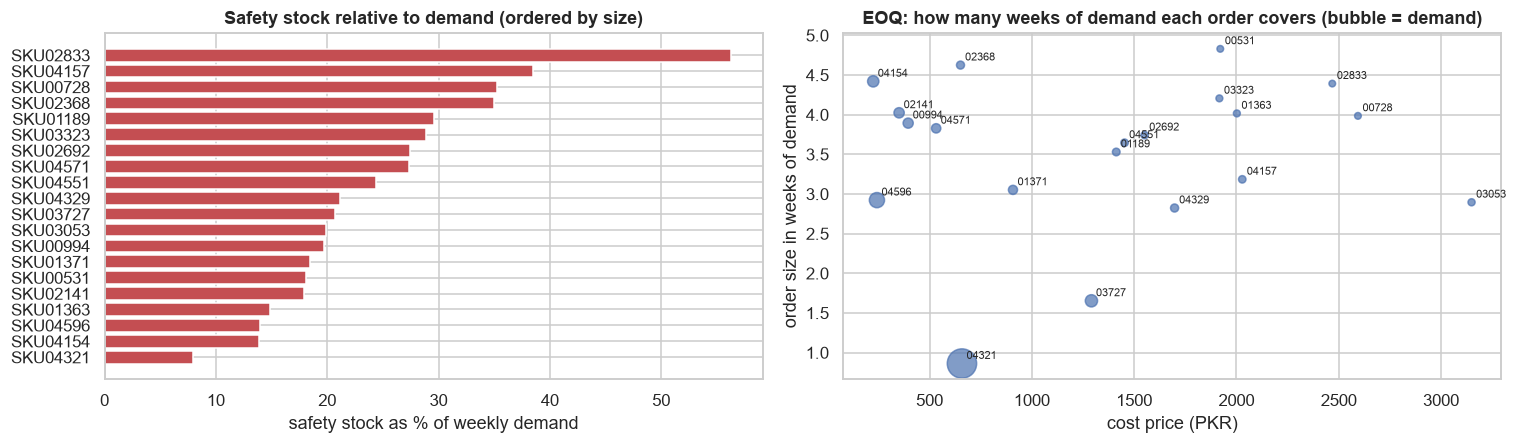

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
r = (rec['safety_stock'] / rec['forecast_weekly'] * 100).sort_values()
ax[0].barh(r.index, r, color='C3')
ax[0].set_xlabel('safety stock as % of weekly demand'); ax[0].set_title('Safety stock relative to demand (ordered by size)')
ax[1].scatter(rec['cost_price'], rec['eoq_weeks_of_demand'], s=rec['forecast_weekly'] / 15 + 15, alpha=.7)
for s_, row in rec.iterrows():
    ax[1].annotate(s_[-5:], (row['cost_price'], row['eoq_weeks_of_demand']), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[1].set_xlabel('cost price (PKR)'); ax[1].set_ylabel('order size in weeks of demand')
ax[1].set_title('EOQ: how many weeks of demand each order covers (bubble = demand)')
plt.tight_layout(); save('06a_recommendations'); plt.show()

**Insights — January recommendations**
- **Safety stock is 8–56% of a week's demand** (median 21%). The big, steady sellers need proportionally the least (8% for `SKU04321`), and small, noisy items the most (56% for `SKU02833`). This follows directly from Step 5's forecast accuracy.
- **Order sizes (EOQ) cover 1–5 weeks of demand**, i.e. 11–60 orders a year. Cheap, fast-moving items are ordered in bigger batches relative to demand; the top seller is the exception (under a week per order) because its volume is so large that frequent orders are cheaper than holding stock.
- **ABC:** within the top 20, 10 products are A, 7 are B and 3 are C. Across all 5,000 products, every one of the top 20 is class A, so these items deserve the closest stock control.
- January forecasts are **8–21% below the 2025 weekly average** (median 14%), because January is a low month. Reorder points set from the 2025 average, or from the December peak, would overstock in January.

## 4. Simulation on the 52 weeks of 2025
Each week: deliveries arrive, customers buy what is on the shelf (demand = recorded + lost units), and the policy decides whether to order.
Orders arrive one week later. Three policies, all starting with the same stock:

| Policy | Rule |
|---|---|
| **Recommended (seasonal)** | Each week, ROP and EOQ are recomputed from the forecast for the coming week (same week last year × recent growth, using only past data) and the 2024 forecast-error σ. If stock + on order ≤ ROP, order the smallest multiple of EOQ that lifts it above ROP. |
| **Static (guide formula)** | One fixed ROP and EOQ for the whole year, from 2024 average demand and the raw demand std. |
| **Naive** | Each week, order what sold that week. |

Costs: holding = average stock × cost price × 20% per year; ordering = PKR 5,000 per order.

In [6]:
y25 = demand.loc['2025']
sig_seasonal = sigma['std of forecast error (used)']
results, sims = [], {}
for s_ in SKUS:
    cost = info.loc[s_, 'cost_price']
    f_next = fc_hist[s_].shift(-1).loc['2025']                      # decision at end of week t protects week t+1
    f_next = f_next.fillna(fc_hist[s_].loc['2025'].iloc[-1])
    rop_dyn = reorder_point(f_next, safety_stock(Z, sig_seasonal[s_], L), L).to_numpy()
    q_dyn = eoq(f_next, S, H, cost).to_numpy()
    d24, s24 = demand.loc['2024', s_].mean(), demand.loc['2024', s_].std()
    rop_st, q_st = reorder_point(d24, safety_stock(Z, s24, L), L), eoq(d24, S, H, cost)
    start = rop_dyn[0] + q_dyn[0]
    runs = {'Recommended (seasonal)': simulate(y25[s_], rop_dyn, q_dyn, start, L),
            'Static (guide formula)': simulate(y25[s_], rop_st, q_st, start, L),
            'Naive': simulate_naive(y25[s_], start, L)}
    sims[s_] = runs | {'rop': rop_dyn, 'rop_static': rop_st}
    for p, r in runs.items():
        results.append({'sku_id': s_, 'policy': p, 'fill_rate_%': r['fill_rate_%'], 'stockout_weeks': r['stockout_weeks'],
                        'avg_inventory_units': r['avg_inventory'], 'avg_inventory_value': r['avg_inventory'] * cost,
                        'orders': r['orders'], 'holding_cost': r['avg_inventory'] * cost * H, 'ordering_cost': r['orders'] * S,
                        'demand_units': y25[s_].sum()})
sim = pd.DataFrame(results)
sim['total_cost'] = sim['holding_cost'] + sim['ordering_cost']

summary = sim.groupby('policy').apply(lambda g: pd.Series({
    'fill rate % (units)': 100 * (g['fill_rate_%'] / 100 * g['demand_units']).sum() / g['demand_units'].sum(),
    'lowest product fill rate %': g['fill_rate_%'].min(),
    'product-weeks out of stock': g['stockout_weeks'].sum(),
    'avg stock value (PKR m)': g['avg_inventory_value'].sum() / 1e6,
    'orders placed': g['orders'].sum(),
    'holding cost (PKR m)': g['holding_cost'].sum() / 1e6,
    'ordering cost (PKR m)': g['ordering_cost'].sum() / 1e6,
    'total cost (PKR m)': g['total_cost'].sum() / 1e6}), include_groups=False).loc[['Recommended (seasonal)', 'Static (guide formula)', 'Naive']]
pd.set_option('display.float_format', '{:,.2f}'.format)
summary

,fill rate % (units),lowest product fill rate %,product-weeks out of stock,avg stock value (PKR m),orders placed,holding cost (PKR m),ordering cost (PKR m),total cost (PKR m)
policy,,,,,,,,
Recommended (seasonal),100.00,99.91,1.00,10.98,347.00,2.20,1.74,3.93
Static (guide formula),99.91,99.61,6.00,11.08,357.00,2.22,1.78,4.00
Naive,100.00,100.00,0.00,17.51,"1,040.00",3.50,5.20,8.70


In [7]:
base = summary.loc['Naive']; best = summary.loc['Recommended (seasonal)']
print(f"Recommended vs naive: fill rate {best.iloc[0]:.2f}% vs {base.iloc[0]:.2f}% | stock value {best['avg stock value (PKR m)'] / base['avg stock value (PKR m)'] - 1:+.0%} | "
      f"orders {best['orders placed'] / base['orders placed'] - 1:+.0%} | total cost {best['total cost (PKR m)'] / base['total cost (PKR m)'] - 1:+.0%}")

Recommended vs naive: fill rate 100.00% vs 100.00% | stock value -37% | orders -67% | total cost -55%


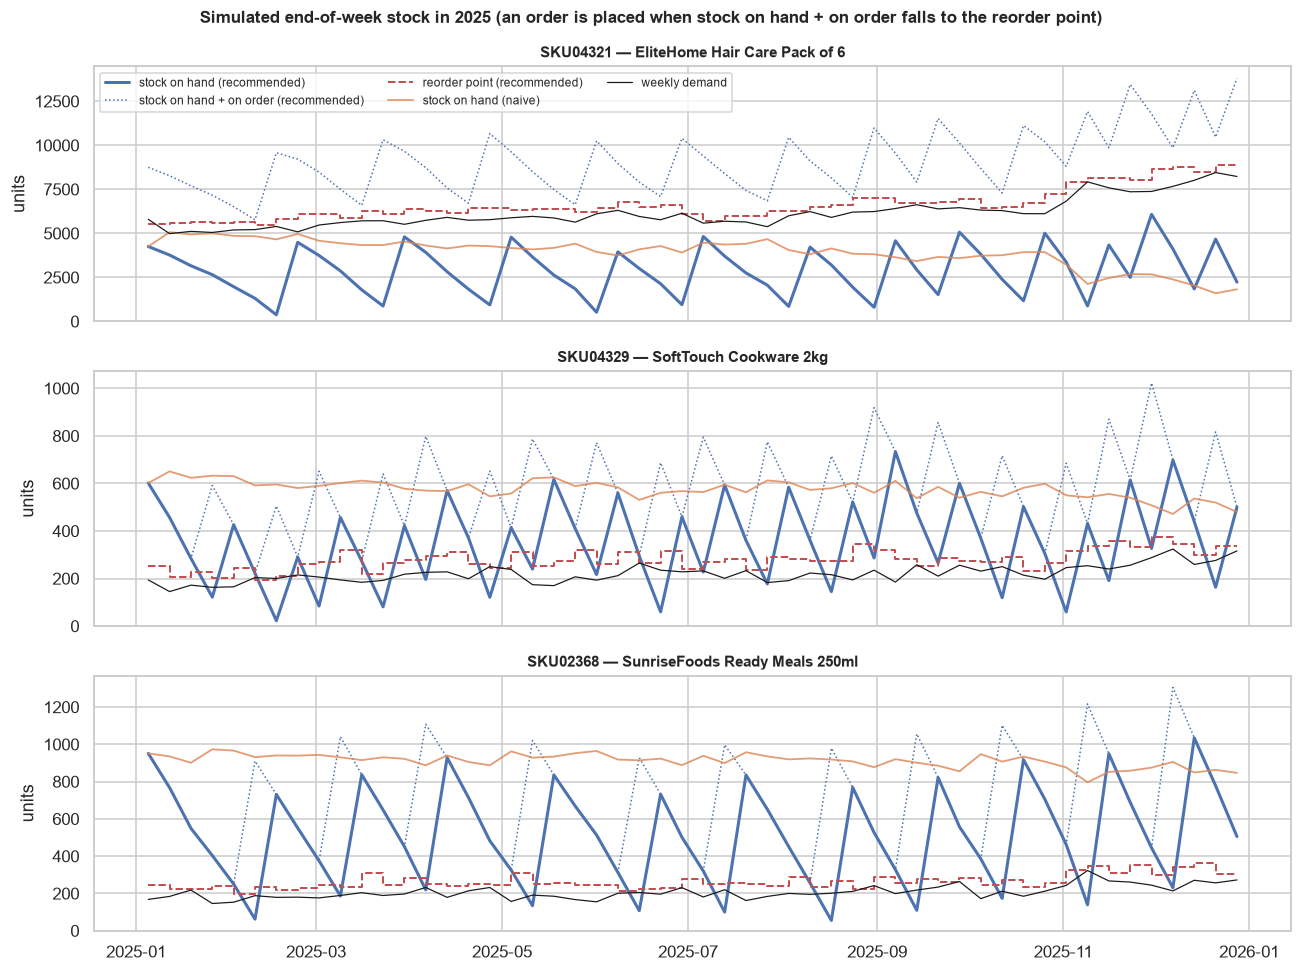

In [8]:
show = [SKUS[0], 'SKU04329', SKUS[-1]]
fig, ax = plt.subplots(len(show), 1, figsize=(12, 9), sharex=True)
weeks = y25.index
for a, s_ in zip(ax, show):
    r = sims[s_]
    rr = r['Recommended (seasonal)']
    a.plot(weeks, rr['levels'], color='C0', lw=2, label='stock on hand (recommended)')
    a.plot(weeks, rr['levels'] + rr['order_qty'], color='C0', lw=1, ls=':', label='stock on hand + on order (recommended)')
    a.step(weeks, r['rop'], where='post', color='C3', ls='--', lw=1.3, label='reorder point (recommended)')
    a.plot(weeks, r['Naive']['levels'], color='C1', lw=1.2, alpha=.8, label='stock on hand (naive)')
    a.plot(weeks, y25[s_], color='k', lw=.8, label='weekly demand')
    a.set_title(f"{s_} — {info.loc[s_, 'sku_name']}", fontsize=10); a.set_ylabel('units'); a.set_ylim(bottom=0)
ax[0].legend(ncol=3, fontsize=8, loc='upper left')
plt.suptitle('Simulated end-of-week stock in 2025 (an order is placed when stock on hand + on order falls to the reorder point)',
             fontweight='bold', fontsize=11); plt.tight_layout()
save('06b_simulation'); plt.show()

**Insights — simulation**
- **All three policies keep almost every customer served** (fill rate ~99.9–100%). Demand here is smooth and the lead time is only a week, so running out is rare whatever the rule.
- **The difference is cost.** Compared with the naive policy, the recommended policy holds **37% less stock** (PKR 11.0m vs 17.5m on average) and places **67% fewer orders** (347 vs 1,040). Total holding + ordering cost falls by **55%** (PKR 3.9m vs 8.7m a year for these 20 products), at the same service. This is the guide's target story: *equal fill rate with much less stock*.
- **The static guide formula** (one fixed reorder point for the year, from raw demand variation) holds about the same stock as the recommended policy but runs out in **6 product-weeks**, during the Nov–Dec peak when demand rises above its fixed reorder point. Seasonal reorder points avoid this.
- **The naive policy has a hidden risk:** it orders what sold last week, so it always lags rising demand. For the top seller its stock drifts down from ~4,200 to ~1,800 units through 2025 as demand grows. It only avoids stockouts because it started with a large stock.

## 5. Status flags
Following the guide: the current stock position is the recommended policy's simulated stock + on-order at the end of 2025; it is compared with the January reorder point.
- **Reorder now**: stock position ≤ ROP · **Overstock**: stock position > ROP + 2 × EOQ · otherwise **OK**

For reference, the dataset's own snapshot is also shown. It covers only some stores for each top product, mostly stores that were out of stock (the injected stockouts),
and its reorder points are set per store. Comparing them with the recommended reorder point split evenly over the 30 stores shows how far the current settings are from demand.

In [9]:
rec['stock_position'] = [sims[s_]['Recommended (seasonal)']['levels'][-1] + sims[s_]['Recommended (seasonal)']['order_qty'][-1] for s_ in SKUS]
rec['status'] = np.select([rec['stock_position'] <= rec['reorder_point'],
                           rec['stock_position'] > rec['reorder_point'] + 2 * rec['eoq']], ['Reorder now', 'Overstock'], 'OK')

snap = pd.read_csv(PROC / 'inventory_features.csv')
snap = snap[snap['sku_id'].isin(SKUS)].groupby('sku_id').agg(snapshot_stores=('store_id', 'nunique'),
        snapshot_out_of_stock=('out_of_stock', 'sum'), current_rop_per_store=('reorder_point', 'mean'))
rec = rec.join(snap)
rec['recommended_rop_per_store'] = rec['reorder_point'] / 30
rec['current_rop_days_of_demand'] = rec['current_rop_per_store'] / (rec['forecast_weekly'] / 30 / 7)
display(rec['status'].value_counts().to_frame('products'))
rec['weeks_of_cover'] = rec['stock_position'] / rec['forecast_weekly']
rec[['stock_position', 'weeks_of_cover', 'reorder_point', 'eoq', 'status', 'snapshot_stores', 'snapshot_out_of_stock',
     'current_rop_per_store', 'recommended_rop_per_store', 'current_rop_days_of_demand']]

,products
status,
OK,20


,stock_position,weeks_of_cover,reorder_point,eoq,status,snapshot_stores,snapshot_out_of_stock,current_rop_per_store,recommended_rop_per_store,current_rop_days_of_demand
sku_id,,,,,,,,,,
SKU04321,"13,803.12",2.60,"5,733.47","4,580.36",OK,10,9,58.10,191.12,2.30
SKU03727,"2,775.23",3.77,889.38,"1,218.18",OK,17,16,61.06,29.65,17.40
SKU04329,500.33,2.60,232.82,542.54,OK,17,17,49.76,7.76,54.38
SKU04596,"5,221.92",4.16,"1,428.79","3,664.36",OK,11,10,64.36,47.63,10.78
SKU01371,808.56,2.63,364.38,938.64,OK,13,12,59.00,12.15,40.28
SKU03053,180.64,1.83,118.07,285.16,OK,14,13,49.57,3.94,105.70
SKU01189,338.46,2.29,191.48,521.56,OK,10,9,51.80,6.38,73.61
SKU04551,687.95,5.11,167.43,490.85,OK,18,17,69.89,5.58,109.00
SKU04157,267.95,2.12,175.00,402.50,OK,14,13,71.79,5.83,119.28


**Insights — status flags**
- With the guide's rule, **all 20 products are "OK"** going into January: each holds 1.8–7 weeks of cover (median 2.7), above its reorder point and below the overstock line. This is the simulated recommended policy, so it shows the policy keeping stock in range rather than real current stock.
- **The dataset's own reorder points ignore demand.** They are a flat ~50–70 units per store for every product, which is only **~2 days of demand** for the top seller (`SKU04321`) but **2–8 months** for the smallest items. Switching to demand-based reorder points would raise them for the 1–3 biggest sellers and cut them sharply for the rest, freeing cash.
- The snapshot rows for these products are mostly out of stock (they are the injected stockouts), which is why the snapshot cannot be used as "current stock" for the whole chain.

## 6. Checking stock rules against the answer key
The dataset's `sku_inventory_flags.csv` marks which store × product rows had an injected **stockout** or are **slow movers** (overstocked, rarely sold).
Simple rules are scored on all 21,228 store × product rows of the snapshot (Step 2's `inventory_features.csv`): **precision** = share of flagged rows that are correct,
**recall** = share of true cases found. Two kinds of rule are compared: rules that read the **stock snapshot**, and rules that use **sales history only**.

In [10]:
inv = pd.read_csv(PROC / 'inventory_features.csv')
fast = inv['avg_daily_units_365'] >= inv['avg_daily_units_365'].quantile(0.75)
slow = inv['avg_daily_units_365'] <= inv['avg_daily_units_365'].quantile(0.50)
rules = {
    ('Stockout risk', 'Stock snapshot: out of stock'): (inv['out_of_stock'] == 1, 'label_stockout_risk'),
    ('Stockout risk', 'Stock snapshot: at or below reorder point'): (inv['below_reorder_point'] == 1, 'label_stockout_risk'),
    ('Stockout risk', 'Sales only: fast seller (top 25%)'): (fast, 'label_stockout_risk'),
    ('Slow mover', 'Stock snapshot: > 3x reorder point and no restock for 90+ days'):
        ((inv['stock_to_reorder_point'] > 3) & (inv['days_since_restock'] > 90), 'label_slow_mover'),
    ('Slow mover', 'Sales only: slow seller (bottom 50%) and no sale for 30+ days'):
        (slow & (inv['days_since_last_sale'] > 30), 'label_slow_mover'),
}
rows = []
for (target, rule), (pred, label) in rules.items():
    y = inv[label] == 1; tp = (pred & y).sum()
    rows.append({'target': target, 'rule': rule, 'rows flagged': int(pred.sum()), 'true cases': int(y.sum()),
                 'precision %': 100 * tp / max(pred.sum(), 1), 'recall %': 100 * tp / y.sum()})
pd.set_option('display.float_format', '{:,.1f}'.format)
pd.DataFrame(rows).set_index(['target', 'rule'])

rows flagged  true cases  precision %  recall %
target        rule                                                                                               
Stockout risk Stock snapshot: out of stock                                2810        2737         97.4     100.0
              Stock snapshot: at or below reorder point                   5862        2737         46.7     100.0
              Sales only: fast seller (top 25%)                           5377        2737         50.9     100.0
Slow mover    Stock snapshot: > 3x reorder point and no resto...          9062        9094        100.0      99.6
              Sales only: slow seller (bottom 50%) and no sal...          6137        9094         67.3      45.4

**Insights — answer-key check**
- **Rules that read the stock snapshot find the anomalies almost perfectly:** "out of stock" finds 100% of stockout-risk rows at 97% precision, and "> 3× reorder point and no restock for 90+ days" finds 99.6% of slow movers at 100% precision. This confirms Step 2's finding that the anomalies were injected directly into the snapshot.
- **Sales history alone is much weaker:** "fast seller" finds every stockout-risk row but only half of its flags are right (51% precision), and the sales-only slow-mover rule finds 45% of slow movers at 67% precision.
- In practice, stock-level monitoring is the reliable alarm, and sales patterns are a useful second signal when stock data is missing or wrong.

## 7. Save outputs

In [11]:
out_cols = ['sku_name', 'category', 'abc_top20', 'abc_all_products', 'unit_price', 'cost_price', 'avg_weekly_demand_2025',
            'forecast_weekly', 'sigma', 'safety_stock', 'reorder_point', 'eoq', 'eoq_weeks_of_demand', 'orders_per_year',
            'stock_position', 'status', 'current_rop_per_store', 'recommended_rop_per_store']
rec[out_cols].rename_axis('sku_id').to_csv(PROC / 'inventory_recommendations.csv', float_format=FLOAT)
sim.to_csv(PROC / 'inventory_simulation.csv', index=False, float_format=FLOAT)
print('saved inventory_recommendations.csv', rec[out_cols].shape, 'and inventory_simulation.csv', sim.shape)

saved inventory_recommendations.csv (20, 18) and inventory_simulation.csv (60, 11)


**Done-when check (Step 6)**
- ✅ 20-row recommendations table with safety stock, reorder point, EOQ, ABC and Status → `data/processed/inventory_recommendations.csv`
- ✅ Simulation over the 52 weeks of 2025 against a naive policy (and the guide's static formula), with fill rate, stock and cost → `data/processed/inventory_simulation.csv`
- ✅ Chart of simulated stock for 3 products with the reorder point drawn on it (`reports/figures/06b_simulation.png`)
- ✅ Assumptions stated (lead time, service level, ordering and holding cost)
- ✅ Stock rules scored against the answer key (precision and recall)

**Carry forward**
- **Step 7 (MLOps):** track the forecast error per SKU over time; if it grows, safety stocks must be recalculated.
- **Dashboard (Step 8):** show the recommendations table with Status, and the simulation chart.